In [1]:
from typing import Set, List
import warnings
from itertools import product
import copy
import joblib

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from catboost import Pool

from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge

from src.losses import xgb_cmse_objective
from src.losses import xgb_cmse_metric
from src.losses import CensoredMeanSquaredErrorObjective
from src.losses import CensoredMeanSquaredErrorMetric
from src.losses import evaluate

In [2]:
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

In [3]:
RANDOM_SEED = 42

In [4]:
X_train = pd.read_csv("../data/processed/X_train.csv").drop(columns=["fail"])
X_val = pd.read_csv("../data/processed/X_val.csv").drop(columns=["fail", 'serial_number'])

In [5]:
y_train = X_train.pop('rul_lb')
y_val = X_val.pop('rul_lb')

In [6]:
required_columns = list(X_train.columns.to_list())

In [7]:
def select_columns(df: pd.DataFrame, required_columns: List[str]) -> pd.DataFrame:
    current_columns = set(df.columns.to_list())
    diff = set(required_columns) - current_columns
    if diff:
        raise ValueError(f'Lack of features: {diff}')
    return df[required_columns]

In [8]:
selector = FunctionTransformer(
    func=select_columns,
    kw_args={'required_columns' : required_columns}
)

In [9]:
transformer = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'), ['model']),
    ],
    remainder=StandardScaler()
)

In [10]:
catboost_pipeline = Pipeline(
    steps=[
        ('selector', selector),
        ('model', CatBoostRegressor(
            random_seed=RANDOM_SEED,
            eval_metric=CensoredMeanSquaredErrorMetric(),
            objective=CensoredMeanSquaredErrorObjective(),
            verbose=False,
            early_stopping_rounds=100
        ))
    ]
)

In [11]:
xgboost_pipeline = Pipeline(
    steps=[
        ('transformer', transformer),
        ('model', XGBRegressor(
            random_state=RANDOM_SEED,
            objective=xgb_cmse_objective,
            eval_metric=xgb_cmse_metric,
            early_stopping_rounds=100,
            enable_categorical=True
        ))
    ]
)

In [12]:
linear_regression_pipeline = Pipeline(
    steps=[
        ('selector', selector),
        ('transformer', transformer),
        ('model', Ridge()),
    ]
)

In [13]:
def calculate_sample_weights(y: pd.Series):
    count_all = len(y)
    count_fail = (y != 60).sum()

    fail_weight = (count_all - count_fail) / count_fail
    normal_weight = 1
    return np.array([fail_weight if x != 60 else normal_weight for x in list(y)])

In [14]:
train_weights = calculate_sample_weights(y_train)
val_weights = calculate_sample_weights(y_val)

In [15]:
tr = clone(transformer)
tr.fit(X_train)

xbg_fit_kwargs = {
    'X' : X_train,
    'y' : y_train,
    'model__sample_weight': train_weights,
    'model__eval_set': [(tr.transform(X_val), y_val)],
    'model__sample_weight_eval_set': [val_weights],
    'model__verbose' : False
}

In [16]:
cat_fit_kwargs = {
    'X' : X_train,
    'y' : y_train,
    'model__sample_weight': train_weights,
    'model__cat_features' : ['model'],
    'model__eval_set': Pool(X_val, y_val, weight=val_weights, cat_features=['model'])
}

In [17]:
catboost_hp = {
    'learning_rate' : [0.01, 0.03, 0.1],  # (0, 1]
    'depth' : [4, 6, 8],                    # depth of each tree [1, 16]
    'min_data_in_leaf' : [1, 10],
    'reg_lambda' : [1, 10]
}

In [18]:
xgboost_hp = {
    'learning_rate': [0.01, 0.05, 0.1, 0.3],
    'max_depth': [4, 6, 8],
    'min_child_weight' : [1, 10],
    'reg_lambda' : [1, 10]
}

In [19]:
def add_prefix(keys, prefix):
    return [prefix + key for key in keys]

In [20]:
def tune_model_hp(md, hps, fit_kwargs, X_train, y_train, X_val, y_val):
    formatted_fit_kwargs = {
        key : value
        for key, value in fit_kwargs.items()
    }

    rows = []
    for values in (product(*hps.values())):
        formatted_kwargs = {
            key : value
            for key, value in zip(add_prefix(hps.keys(), 'model__'), values)
        }
        model = copy.deepcopy(md)
        model.set_params(**formatted_kwargs)

        model.fit(**formatted_fit_kwargs)

        error_train, weights_train = evaluate(model.predict(X_train), y_train)
        error_val, weights_val = evaluate(model.predict(X_val), y_val)

        rows.append(list(values)+ [error_train / weights_train, error_val / weights_val])

    return pd.DataFrame(rows, columns=list(hps.keys()) + ['train cmse', 'val cmse'])

In [21]:
cat_results = tune_model_hp(catboost_pipeline, catboost_hp, cat_fit_kwargs, X_train, y_train, X_val, y_val)

In [22]:
cat_results.sort_values(by=['val cmse'], inplace=True, ascending=True)

In [23]:
xgb_results = tune_model_hp(xgboost_pipeline,xgboost_hp, xbg_fit_kwargs, X_train, y_train, X_val, y_val)

In [24]:
xgb_results.sort_values(by=['val cmse'], inplace=True, ascending=True)

In [25]:
cat_results.head()

,learning_rate,depth,min_data_in_leaf,reg_lambda,train cmse,val cmse
24,0.10,4,1,1,55.022023,55.963714
26,0.10,4,10,1,55.022023,55.963714
25,0.10,4,1,10,56.938504,58.133271
27,0.10,4,10,10,56.938504,58.133271
15,0.03,4,10,10,58.758960,59.531124


In [26]:
xgb_results.head()

,learning_rate,max_depth,min_child_weight,reg_lambda,train cmse,val cmse
41,0.3,6,1,10,41.462425,42.777061
43,0.3,6,10,10,41.465248,42.780598
38,0.3,4,10,1,45.782825,47.027706
25,0.1,4,1,10,51.873135,52.591503
36,0.3,4,1,1,52.767658,53.847786


In [27]:
lin_reg = tune_model_hp(linear_regression_pipeline, {'max_iter' : [100, 500, 1000]}, {'X' : X_train, 'y' : y_train}, X_train, y_train, X_val, y_val)

In [28]:
lin_reg.head()

,max_iter,train cmse,val cmse
0,100,2.177325,2.249573
1,500,2.177325,2.249573
2,1000,2.177325,2.249573


Let's compare best boosting result and suspiciously good linear regression results.

In [29]:
best_boosting = copy.deepcopy(xgboost_pipeline)
best_boosting.set_params(**{
            key : value
            for key, value in zip(add_prefix(xgboost_hp.keys(), 'model__'), [0.3,6,1,10])
        })
best_boosting.fit(**xbg_fit_kwargs)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](221,)","['model','capacity_bytes','smart_1_raw_day',...,'smart_246_raw_month', 'smart_247_raw_month','smart_248_raw_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,221
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

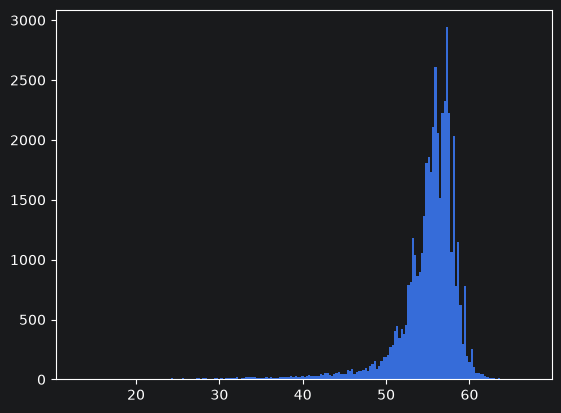

In [30]:
y_val_pred = best_boosting.predict(X_val)
plt.hist(y_val_pred[y_val == 60], bins=200)
plt.show()

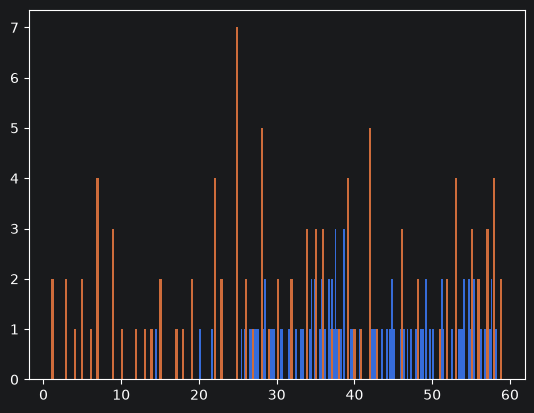

In [31]:
plt.hist(y_val_pred[y_val != 60], bins=200)
plt.hist(y_val[y_val != 60], bins=200)
plt.show()

In [32]:
errors = np.abs(y_val_pred - y_val)
mask_low = (y_val != 60) & (y_val <= 15)
mask_high = (y_val != 60) & (y_val > 15)

print('низкий RUL, средняя ошибка:', errors[mask_low].mean())
print('высокий RUL, средняя ошибка:', errors[mask_high].mean())

низкий RUL, средняя ошибка: 28.957914897373744
высокий RUL, средняя ошибка: 12.786638549611538


In [33]:
lin_reg = clone(linear_regression_pipeline)
lin_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selector', ...), ('transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](221,)","['model','capacity_bytes','smart_1_raw_day',...,'smart_246_raw_month', 'smart_247_raw_month','smart_248_raw_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,221
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function sel...t 0x11757c670>
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18","{'required_columns': ['model', 'capacity_bytes', ...]}"
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


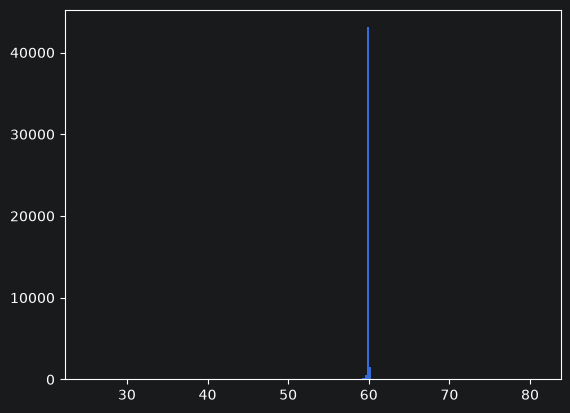

In [34]:
y_val_pred_reg = lin_reg.predict(X_val)
plt.hist(y_val_pred_reg[y_val == 60], bins=200)
plt.show()

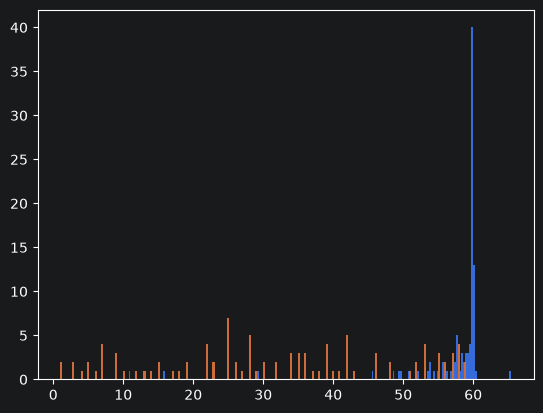

In [35]:
plt.hist(y_val_pred_reg[y_val != 60], bins=200)
plt.hist(y_val[y_val != 60], bins=200)
plt.show()

In [36]:
train_weights_div_target = train_weights / y_train
val_weights_div_target = val_weights / y_val

In [37]:
xbg_fit_kwargs_new = copy.deepcopy(xbg_fit_kwargs)
xbg_fit_kwargs_new['model__sample_weight'] = train_weights_div_target
xbg_fit_kwargs_new['model__sample_weight_eval_set'] = [val_weights_div_target]

In [38]:
best_boosting = copy.deepcopy(xgboost_pipeline)
best_boosting.set_params(**{
            key : value
            for key, value in zip(add_prefix(xgboost_hp.keys(), 'model__'), [0.3,6,1,10])
        })
best_boosting.fit(**xbg_fit_kwargs_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](221,)","['model','capacity_bytes','smart_1_raw_day',...,'smart_246_raw_month', 'smart_247_raw_month','smart_248_raw_month']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,221
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

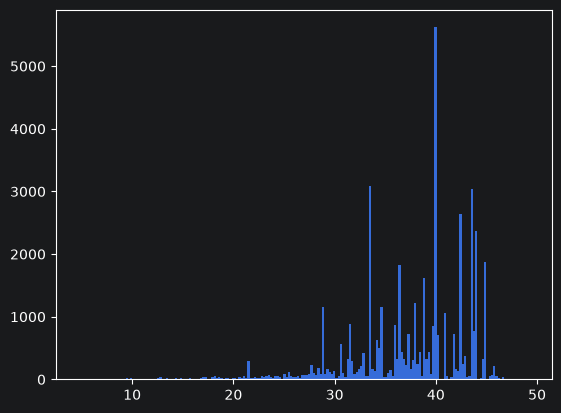

In [39]:
y_val_pred = best_boosting.predict(X_val)
plt.hist(y_val_pred[y_val == 60], bins=200)
plt.show()

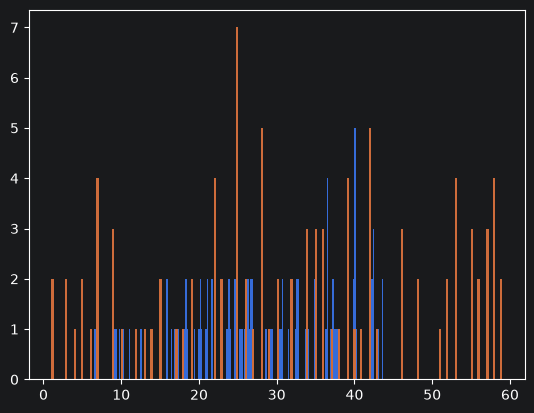

In [40]:
plt.hist(y_val_pred[y_val != 60], bins=200)
plt.hist(y_val[y_val != 60], bins=200)
plt.show()

In [41]:
xgb_results_new = tune_model_hp(xgboost_pipeline,xgboost_hp, xbg_fit_kwargs_new, X_train, y_train, X_val, y_val)

In [42]:
xgb_results_new.sort_values(by=['val cmse'], inplace=True, ascending=True)
xgb_results_new.head()

,learning_rate,max_depth,min_child_weight,reg_lambda,train cmse,val cmse
37,0.30,4,1,10,483.784607,484.597351
39,0.30,4,10,10,484.297668,485.048645
43,0.30,6,10,10,514.434814,515.228149
27,0.10,4,10,10,516.639221,516.774170
14,0.05,4,10,1,519.611145,519.678894


In [43]:
errors = np.abs(y_val_pred - y_val)
mask_low = (y_val != 60) & (y_val <= 15)
mask_high = (y_val != 60) & (y_val > 15)

print('низкий RUL, средняя ошибка:', errors[mask_low].mean())
print('высокий RUL, средняя ошибка:', errors[mask_high].mean())

низкий RUL, средняя ошибка: 18.819398698352632
высокий RUL, средняя ошибка: 14.117788169957414


As we can see, changing the weights somewhat improved training: although for samples that didn't fail within our available observation window, the results appear visually skewed to the left, and the mean absolute error there actually increased slightly, from 12 to 14 days. Meanwhile, for the disks that did fail, it decreased from 28 to 18 days. I can conclude that this reweighting achieves a better balance overall. As the final model, I'll go with XGBoost trained with these weights.

In [44]:
joblib.dump(best_boosting, '../models/xgb_model.joblib')

['../models/xgb_model.joblib']